# 01 · Exploratory Data Analysis

**Dataset:** [Twitter US Airline Sentiment](https://www.kaggle.com/datasets/crowdflower/twitter-airline-sentiment) (CrowdFlower, CC BY-NC-SA 4.0). 14,640 tweets about six US airlines from February 2015, each labeled positive, neutral or negative by human annotators, with a complaint reason for negative tweets.

## Business context

Twitter is where airline customers complain in public. A **Customer Experience / Social Care** team has limited people, so it needs to know where to focus.

## Business questions

1. **How negative is public conversation about airlines?**
2. **Which airlines have the worst and best reputation on Twitter?**
3. **What drives complaints:** operations (delays, cancellations) or customer service?
4. **What should the Customer Experience team prioritize?**

## Summary of findings

- **62.7%** of tweets are negative and only 16.1% positive: customers use Twitter mainly to complain.
- **US Airways** has the worst reputation (77.7% negative), **Virgin America** the best (35.9%).
- United, US Airways and American produce 64% of tweets but **74% of negative tweets**.
- **Customer service** drives 31.7% of complaints, more than late and cancelled flights combined (27.3%).
- Two data quality issues were fixed before the analysis: **155 duplicate tweets** and a **"Delta" label that most likely refers to JetBlue** (section 3).

## Contents

1. Setup
2. Data overview
3. Data quality and cleaning
4. Q1 · Overall sentiment
5. Q2 · Sentiment by airline
6. Q3 · Complaint drivers
7. Tweet length
8. Example tweets and word clouds
9. Conclusions, recommendations and limitations (Q4)

## 1. Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import re
import seaborn as sns
from wordcloud import WordCloud

sys.path.insert(0, str(Path.cwd().parent))
from src.data import RAW_PATH, build_dashboard_data

pd.set_option("display.max_colwidth", 150)
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

# Same colors as the dashboard: a diverging red / gray / blue for sentiment.
SENTIMENTS = ["negative", "neutral", "positive"]
COLORS = {"negative": "#e34948", "neutral": "#a8a79f", "positive": "#2a78d6"}

## 2. Data overview

In [2]:
raw = pd.read_csv(RAW_PATH)
print(f"{raw.shape[0]:,} rows, {raw.shape[1]} columns")
raw.head()

14,640 rows, 15 columns


,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone
0,570306133677760513,neutral,1.0000,NaN,NaN,Virgin America,NaN,cairdin,NaN,0,@VirginAmerica What @dhepburn said.,NaN,2015-02-24 11:35:52 -0800,NaN,Eastern Time (US & Canada)
1,570301130888122368,positive,0.3486,NaN,0.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica plus you've added commercials to the experience... tacky.,NaN,2015-02-24 11:15:59 -0800,NaN,Pacific Time (US & Canada)
2,570301083672813571,neutral,0.6837,NaN,NaN,Virgin America,NaN,yvonnalynn,NaN,0,@VirginAmerica I didn't today... Must mean I need to take another trip!,NaN,2015-02-24 11:15:48 -0800,Lets Play,Central Time (US & Canada)
3,570301031407624196,negative,1.0000,Bad Flight,0.7033,Virgin America,NaN,jnardino,NaN,0,"@VirginAmerica it's really aggressive to blast obnoxious ""entertainment"" in your guests' faces &amp; they have little recourse",NaN,2015-02-24 11:15:36 -0800,NaN,Pacific Time (US & Canada)
4,570300817074462722,negative,1.0000,Can't Tell,1.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica and it's a really big bad thing about it,NaN,2015-02-24 11:14:45 -0800,NaN,Pacific Time (US & Canada)


Key columns:

| Column | Meaning |
|---|---|
| `airline_sentiment` | Sentiment label from human annotators (negative / neutral / positive) |
| `airline_sentiment_confidence` | Annotator agreement for that label (0–1) |
| `negativereason` | Complaint reason, only for negative tweets |
| `airline` | Airline the tweet is about |
| `text` | Tweet text |
| `tweet_created` | Timestamp (US Pacific offset) |

In [3]:
missing = raw.isna().sum()
missing = pd.DataFrame({"missing": missing, "missing_pct": (missing / len(raw) * 100).round(1)})
missing[missing["missing"] > 0].sort_values("missing", ascending=False)

,missing,missing_pct
negativereason_gold,14608,99.8
airline_sentiment_gold,14600,99.7
tweet_coord,13621,93.0
negativereason,5462,37.3
user_timezone,4820,32.9
tweet_location,4733,32.3
negativereason_confidence,4118,28.1


The sentiment label, airline and text are complete. `negativereason` is empty for non-negative tweets by design. The `_gold` and `tweet_coord` columns are over 90% empty and are not used.

## 3. Data quality and cleaning

### 3.1 Duplicate tweets

In [4]:
dupes = raw[raw.duplicated("tweet_id", keep=False)]
conflicting = dupes.groupby("tweet_id")["airline_sentiment"].nunique().gt(1).sum()
print(f"Duplicate rows (extra copies): {raw.duplicated('tweet_id').sum()}")
print(f"Tweets with conflicting sentiment labels: {conflicting}")
raw[raw.duplicated("tweet_id")].groupby("airline").size().rename("extra copies")

Duplicate rows (extra copies): 155
Tweets with conflicting sentiment labels: 18


airline
American    155
Name: extra copies, dtype: int64

All **155 extra copies** belong to American, and for **18 tweets** the copies carry different sentiment labels. Counting them twice would overstate American's volume, so the cleaning step keeps one copy per tweet: the one with the highest annotator confidence.

### 3.2 Airline labels

In [5]:
mentions = raw.assign(
    mentions_jetblue=raw["text"].str.contains("@jetblue", case=False),
    mentions_delta=raw["text"].str.contains("@delta", case=False),
)
(mentions.groupby("airline")[["mentions_jetblue", "mentions_delta"]].mean() * 100).round(1)

,mentions_jetblue,mentions_delta
airline,,
American,0.3,0.7
Delta,99.8,0.3
Southwest,0.1,0.5
US Airways,0.1,0.5
United,0.1,0.5
Virgin America,0.2,0.0


- **The "Delta" label most likely refers to JetBlue.** 99.8% of the tweets labeled Delta (2,218 of 2,222) are addressed to @JetBlue, while only 0.3% mention @Delta. The source also has no JetBlue label at all, although JetBlue is one of the larger US airlines. Together this points to a labeling error in the source data.
- **Decision:** the analysis treats these tweets as JetBlue (`AIRLINE_FIXES` in `src/data.py`). Results shown for JetBlue in this project rely on that assumption.

### 3.3 Coverage by airline

In [6]:
created = pd.to_datetime(raw["tweet_created"], utc=True).dt.tz_convert("US/Pacific")
coverage = raw.assign(day=created.dt.date).pivot_table(index="airline", columns="day", values="tweet_id", aggfunc="count", fill_value=0)
coverage

day,2015-02-16,2015-02-17,2015-02-18,2015-02-19,2015-02-20,2015-02-21,2015-02-22,2015-02-23,2015-02-24
airline,,,,,,,,,
American,0,0,1,1,1,1,988,1141,626
Delta,2,263,268,283,251,243,408,391,113
Southwest,0,384,292,317,319,370,279,276,183
US Airways,0,311,317,279,333,360,648,488,177
United,2,396,406,426,526,506,703,641,216
Virgin America,0,54,60,70,70,77,53,91,29


The data covers 16–24 Feb 2015, but **American has only 4 tweets before 22 Feb**. Comparisons over time therefore leave American out of the days before 22 Feb, and 16 and 24 Feb are partial days for every airline.

### 3.4 Cleaned dataset

`build_dashboard_data` in `src/data.py` applies the fixes above, plus three smaller ones: the `longlines` reason is renamed to *Long Lines*, the reason is cleared for non-negative tweets, and HTML entities such as `&amp;` are decoded. The same function produces the dashboard data, so every number below matches the dashboard, the SQL analysis (notebook 05) and the README.

In [7]:
df = build_dashboard_data(raw)
print(f"{len(df):,} unique tweets after cleaning ({len(raw) - len(df)} rows removed)")
df.head()

14,485 unique tweets after cleaning (155 rows removed)


,tweet_id,airline,sentiment,negative_reason,tweet_created,text
0,567588278875213824,JetBlue,neutral,NaN,2015-02-16 23:36:05,@JetBlue's new CEO seeks the right balance to please passengers and Wall ... - Greenfield Daily Reporter http://t.co/LM3opxkxch
1,567590027375702016,JetBlue,negative,Can't Tell,2015-02-16 23:43:02,@JetBlue is REALLY getting on my nerves !! 😡😡 #nothappy
2,567591480085463040,United,negative,Late Flight,2015-02-16 23:48:48,@united yes. We waited in line for almost an hour to do so. Some passengers just left not wanting to wait past 1am.
3,567592368451248130,United,negative,Late Flight,2015-02-16 23:52:20,"@united the we got into the gate at IAH on time and have given our seats and closed the flight. If you know people is arriving, have to wait"
4,567594449874587648,Southwest,negative,Customer Service Issue,2015-02-17 00:00:36,"@SouthwestAir its cool that my bags take a bit longer, dont give me baggage blue balls-turn the carousel on, tell me it's coming, then not."


## 4. Q1 · Overall sentiment

In [8]:
sentiment = df["sentiment"].value_counts().reindex(SENTIMENTS)
summary = pd.DataFrame({"tweets": sentiment, "share_pct": (sentiment / len(df) * 100).round(1)})
summary

,tweets,share_pct
sentiment,,
negative,9083,62.7
neutral,3068,21.2
positive,2334,16.1


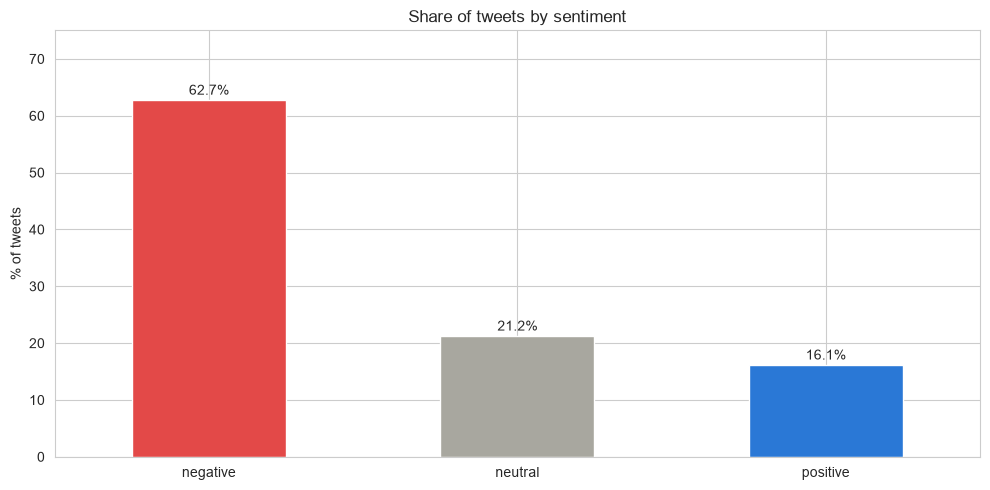

In [9]:
ax = summary["share_pct"].plot(kind="bar", color=[COLORS[s] for s in SENTIMENTS], rot=0)
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=2)
ax.set(title="Share of tweets by sentiment", xlabel="", ylabel="% of tweets", ylim=(0, 75))
plt.tight_layout()
plt.show()

**Finding (Q1):** **62.7%** of tweets are negative and only **16.1%** are positive. Customers use Twitter mainly to complain, so a social care team should expect most of its inbound volume to be complaints.

*For modeling:* the classes are imbalanced (negative dominates), which notebook 03 handles with class weights.

## 5. Q2 · Sentiment by airline

In [10]:
by_airline = pd.crosstab(df["airline"], df["sentiment"], normalize="index")[SENTIMENTS] * 100
by_airline["tweets"] = df["airline"].value_counts()
by_airline = by_airline.sort_values("negative", ascending=False)
by_airline.round(1)

sentiment,negative,neutral,positive,tweets
airline,,,,
US Airways,77.7,13.1,9.2,2913
American,71.6,16.6,11.8,2604
United,68.9,18.2,12.9,3822
Southwest,49.0,27.4,23.6,2420
JetBlue,43.0,32.5,24.5,2222
Virgin America,35.9,33.9,30.2,504


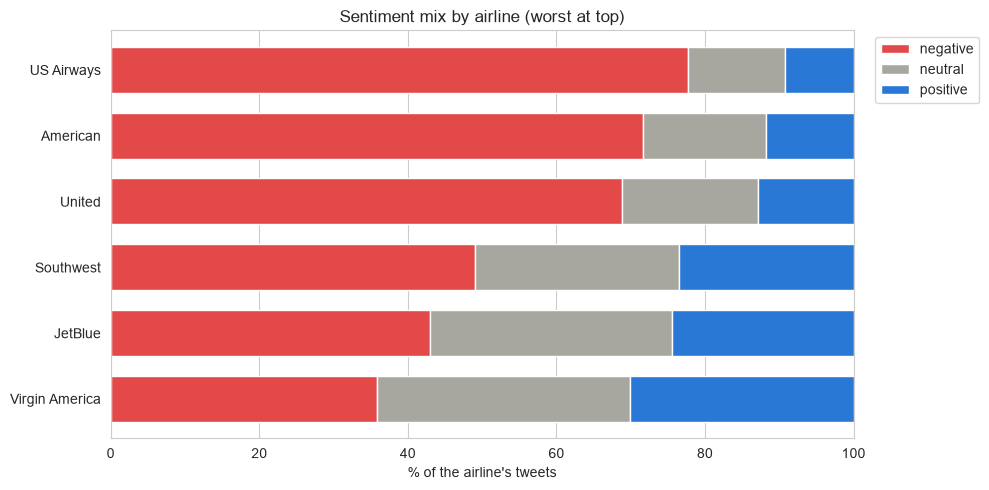

In [11]:
ax = by_airline[SENTIMENTS].iloc[::-1].plot(kind="barh", stacked=True, color=[COLORS[s] for s in SENTIMENTS], width=0.7)
ax.set(title="Sentiment mix by airline (worst at top)", xlabel="% of the airline's tweets", ylabel="", xlim=(0, 100))
ax.legend(title="", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [12]:
big_three = ["United", "US Airways", "American"]
negative = df[df["sentiment"] == "negative"]
print(f"Big three share of all tweets:          {df['airline'].isin(big_three).mean():.1%}")
print(f"Big three share of all negative tweets: {negative['airline'].isin(big_three).mean():.1%}")

Big three share of all tweets:          64.5%
Big three share of all negative tweets: 74.4%


**Findings (Q2):**
- **US Airways** has the worst reputation: **77.7%** of its tweets are negative and only 9.2% positive, followed by **American** (71.6%) and **United** (68.9%).
- **Virgin America** has the best (35.9% negative, 30.2% positive), followed by **JetBlue** (43.0%) and **Southwest** (49.0%).
- The gap between best and worst is **about 42 percentage points**, so a poor reputation is not simply an industry-wide problem.
- United, US Airways and American produce **64%** of tweets but **74%** of negative tweets.

## 6. Q3 · Complaint drivers

In [13]:
reasons = negative["negative_reason"].value_counts()
reasons = pd.DataFrame({"tweets": reasons, "share_pct": (reasons / reasons.sum() * 100).round(1)})
reasons

,tweets,share_pct
negative_reason,,
Customer Service Issue,2881,31.7
Late Flight,1653,18.2
Can't Tell,1180,13.0
Cancelled Flight,830,9.1
Lost Luggage,719,7.9
Bad Flight,573,6.3
Flight Booking Problems,523,5.8
Flight Attendant Complaints,475,5.2
Long Lines,176,1.9


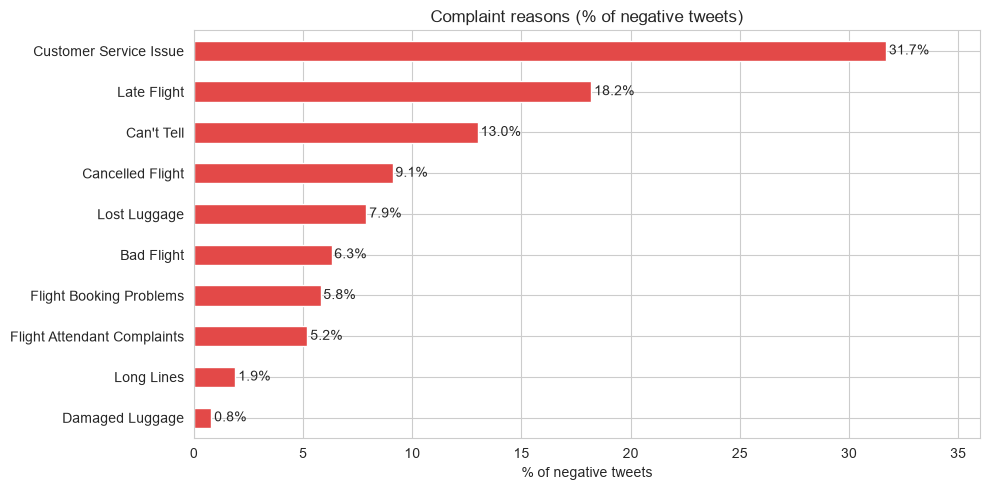

In [14]:
ax = reasons["share_pct"].iloc[::-1].plot(kind="barh", color=COLORS["negative"])
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=2)
ax.set(title="Complaint reasons (% of negative tweets)", xlabel="% of negative tweets", ylabel="", xlim=(0, 36))
plt.tight_layout()
plt.show()

In [15]:
share = reasons["share_pct"]
print(f"Operations (Late + Cancelled Flight):  {share[['Late Flight', 'Cancelled Flight']].sum():.1f}%")
print(f"Baggage (Lost + Damaged Luggage):      {share[['Lost Luggage', 'Damaged Luggage']].sum():.1f}%")

Operations (Late + Cancelled Flight):  27.3%
Baggage (Lost + Damaged Luggage):      8.7%


**Findings (Q3):**
- **Customer Service Issue** is the largest complaint driver at **31.7%** of negative tweets, almost twice **Late Flight** (18.2%).
- **Operational** problems (late and cancelled flights) together account for **27.3%**, still less than customer service alone.
- **Baggage** problems (lost and damaged luggage) account for **8.7%**.
- **13.0%** of complaints are labeled *Can't Tell*: the annotators could not identify a reason from the tweet.

The most common complaint is not the delay itself but **how customers are treated**, which an airline controls far more directly than weather or airport congestion. Notebook 05 breaks this down per airline.

## 7. Tweet length

In [16]:
df["characters"] = df["text"].str.len()
df["words"] = df["text"].str.split().str.len()
df.groupby("sentiment")[["characters", "words"]].mean().reindex(SENTIMENTS).round(1)

,characters,words
sentiment,,
negative,113.7,19.7
neutral,87.3,14.4
positive,86.0,14.0


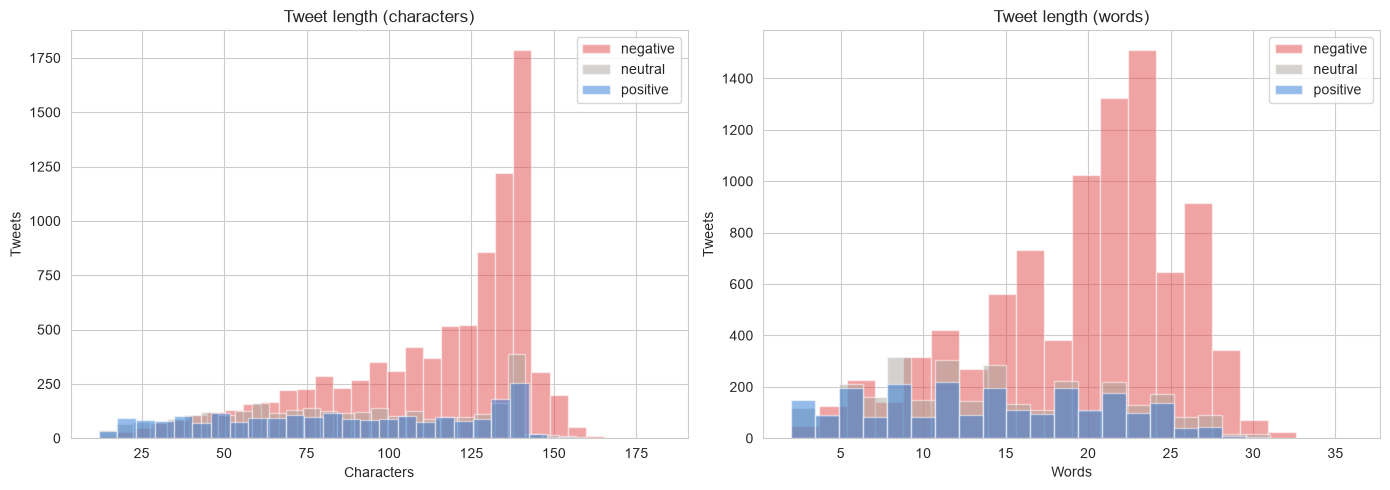

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for s in SENTIMENTS:
    subset = df[df["sentiment"] == s]
    ax[0].hist(subset["characters"], bins=30, alpha=0.5, label=s, color=COLORS[s])
    ax[1].hist(subset["words"], bins=20, alpha=0.5, label=s, color=COLORS[s])
ax[0].set(title="Tweet length (characters)", xlabel="Characters", ylabel="Tweets")
ax[1].set(title="Tweet length (words)", xlabel="Words", ylabel="Tweets")
ax[0].legend()
ax[1].legend()
plt.tight_layout()
plt.show()

**Finding:** negative tweets are longer on average (**113.7 characters / 19.7 words**) than neutral (87.3) and positive (86.0) ones. Unhappy customers tend to describe what went wrong, which gives a social care team the details it needs to follow up.

## 8. Example tweets and word clouds

In [18]:
for s in SENTIMENTS:
    print(s.upper())
    for tweet in df.loc[df["sentiment"] == s, "text"].sample(3, random_state=42):
        print(f"  - {tweet}")
    print()

NEGATIVE
  - @USAirways Who intentionally buys a flight with a 10 hour layover?  And what kind of airline would charge $200 to fix it? Wow... #usairways
  - @United - flight Cancelled Flightled. 4 hrs at airport to book a new one for $95. Just got two invoices for the flight, each for approx $300. Really?!
  - @united I would appreciate an answer on why we weren't alerted flight had been Cancelled Flighted until plane landed.  #showsomerespect

NEUTRAL
  - @VirginAmerica when can I book my flight to Hawaii??
  - @USAirways flights to Dfw Cancelled Flightled today?
  - @USAirways  I need to email customer service for help and a question, can you please provide the email address?

POSITIVE
  - @united Thank you!! 😊
  - @SouthwestAir Thx to customer service rep ALEX for his patient help in reFlight Booking Problems a Cancelled Flighted flight and getting us where we have to be tmrw!
  - @JetBlue thank you



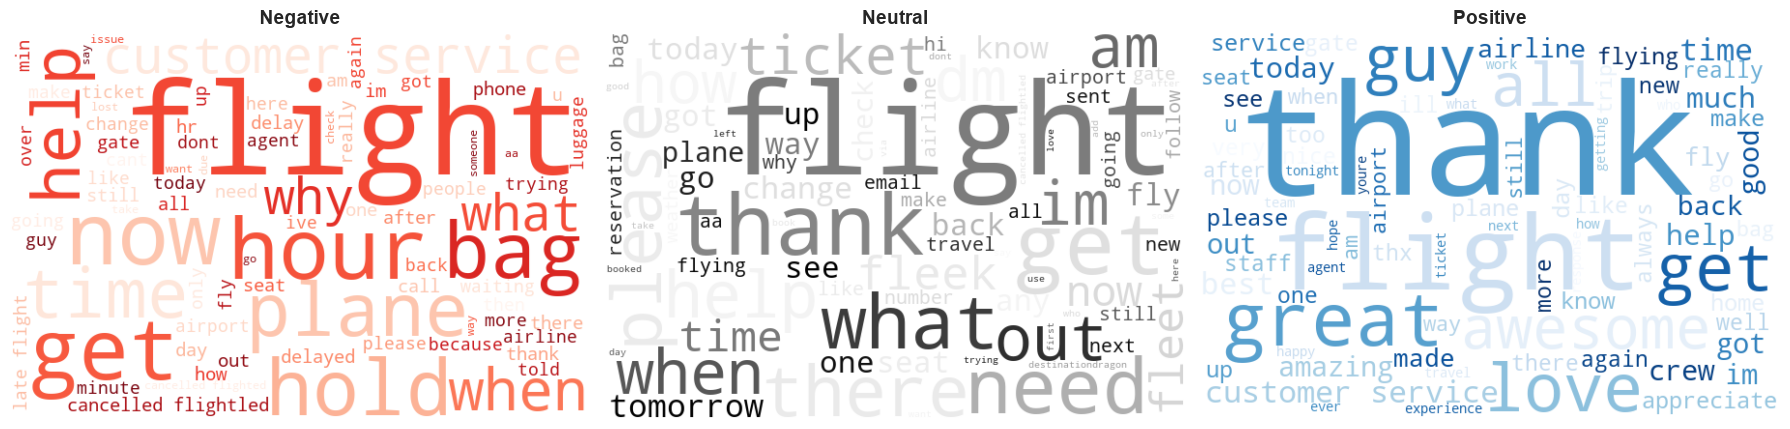

In [19]:
def words_only(text: str) -> str:
    text = text.lower()
    text = re.sub(r"http\S+|www\S+|@\w+", "", text)
    return re.sub(r"[^a-z\s]", "", text)


# Airline names and common filler words would dominate every cloud, so they are left out.
STOPWORDS = {
    "the", "a", "an", "is", "are", "was", "were", "be", "been", "being", "i", "you", "he", "she", "it",
    "we", "they", "them", "us", "me", "my", "your", "his", "her", "its", "our", "their", "to", "of",
    "in", "on", "at", "for", "with", "by", "from", "about", "and", "or", "but", "if", "so", "as",
    "that", "this", "these", "those", "have", "has", "had", "do", "does", "did", "will", "would",
    "could", "should", "can", "just", "not", "no", "yes", "rt", "amp", "united", "usairways",
    "americanair", "southwestair", "jetblue", "virginamerica", "airways", "american", "southwest",
}
CMAPS = {"negative": "Reds", "neutral": "Greys", "positive": "Blues"}

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, s in zip(axes, SENTIMENTS):
    text = " ".join(df.loc[df["sentiment"] == s, "text"].map(words_only))
    cloud = WordCloud(width=600, height=400, background_color="white", stopwords=STOPWORDS,
                      max_words=80, colormap=CMAPS[s], random_state=42).generate(text)
    ax.imshow(cloud, interpolation="bilinear")
    ax.set_title(s.capitalize(), fontsize=14, fontweight="bold")
    ax.axis("off")
plt.tight_layout()
plt.show()

Besides *flight*, negative tweets are dominated by **hour, hold, bag, help** and **customer service**: waiting (on the phone or at the airport) and baggage are common threads. Positive tweets are mostly **thank, great, love** and **awesome**, often about crew and service. The word *flightled* in the negative cloud is an artifact in the source text ("Cancelled Flightled"), not something customers wrote.

## 9. Conclusions, recommendations and limitations

### Answers to the business questions

| Question | Answer |
|---|---|
| **Q1** How negative is the conversation? | **62.7%** of tweets are negative and only 16.1% positive. Twitter is mainly a complaint channel. |
| **Q2** Worst and best reputation? | Worst: **US Airways** (77.7% negative), then American (71.6%) and United (68.9%). Best: **Virgin America** (35.9%), then JetBlue (43.0%). |
| **Q3** What drives complaints? | **Customer Service Issue (31.7%)**, more than late and cancelled flights combined (27.3%). |

### Recommendations (Q4)

1. **Fix customer service before punctuality.** It is the biggest complaint driver and the one airlines control most directly (staff training, response time, empowering agents to resolve issues).
2. **Focus social care resources on United, US Airways and American**, which together generate 74% of negative tweets.
3. **Notify passengers proactively about delays and cancellations**, with automatic rebooking options, so operational problems do not escalate into service complaints.
4. **Benchmark against Virgin America**, whose share of positive tweets (30.2%) is over 3× that of US Airways (9.2%).
5. **Monitor sentiment automatically.** The classifier in notebooks 03–04 flags negative tweets so the social care team does not have to read every tweet manually.

### Limitations

- The data covers **about one week in February 2015**, so seasonal patterns and current conditions are not reflected.
- People who tweet about airlines **skew toward customers who had a problem**, so the negative share likely overstates overall dissatisfaction.
- Complaint reasons are annotator labels, and 13% could not be determined (*Can't Tell*).
- The **"Delta" label is treated as JetBlue** based on the evidence in section 3.2, and **American has almost no tweets before 22 Feb**.
- Tweet volume is not normalized by passenger numbers, so the analysis compares **shares**, not absolute counts.

### Next steps

- **Notebook 02–04:** text preprocessing and a sentiment classifier for automatic monitoring.
- **Notebook 05:** the same questions in SQL, with a per-airline breakdown of complaints and a daily trend.
- **[Dashboard](https://airline-sentiment-antarez.streamlit.app):** the findings above, interactive.

### Handoff to notebook 02

Notebook 02 prepares the tweet text for modeling. It currently starts from the raw data minus the mostly empty columns.

In [20]:
raw.drop(columns=["airline_sentiment_gold", "negativereason_gold", "tweet_coord"]).to_csv(
    "../data/processed/tweets_eda.csv", index=False
)
print("Saved data/processed/tweets_eda.csv")

Saved data/processed/tweets_eda.csv
